In [103]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [104]:
orders = pd.read_csv('/Users/komalrajwani/Downloads/Internship-PRP-Project-1 - 1786970764530/data/orders.csv')
order_items = pd.read_csv('/Users/komalrajwani/Downloads/Internship-PRP-Project-1 - 1786970764530/data/order_items.csv')
order_item_refunds = pd.read_csv('/Users/komalrajwani/Downloads/Internship-PRP-Project-1 - 1786970764530/data/order_item_refunds.csv')
products = pd.read_csv('/Users/komalrajwani/Downloads/Internship-PRP-Project-1 - 1786970764530/data/products.csv')
website_sessions = pd.read_csv('/Users/komalrajwani/Downloads/Internship-PRP-Project-1 - 1786970764530/data/website_sessions.csv')
website_pageviews = pd.read_csv('/Users/komalrajwani/Downloads/Internship-PRP-Project-1 - 1786970764530/data/website_pageviews.csv')

In [105]:
print("Website Sessions:", website_sessions.shape)
print("Website Pageviews:", website_pageviews.shape)
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Order Item Refunds:", order_item_refunds.shape)
print("Products:", products.shape)

Website Sessions: (472871, 9)
Website Pageviews: (1188124, 4)
Orders: (32313, 8)
Order Items: (40025, 7)
Order Item Refunds: (1731, 5)
Products: (4, 3)


In [106]:
orders["created_at"] = pd.to_datetime(orders["created_at"])
order_items["created_at"] = pd.to_datetime(order_items["created_at"])
order_item_refunds["created_at"] = pd.to_datetime(order_item_refunds["created_at"])
products["created_at"] = pd.to_datetime(products["created_at"])
website_sessions["created_at"] = pd.to_datetime(website_sessions["created_at"])
website_pageviews["created_at"] = pd.to_datetime(website_pageviews["created_at"])

In [107]:
print(orders["created_at"].dtype)

datetime64[ns]


In [108]:
orders.isnull().sum()

order_id              0
created_at            0
website_session_id    0
user_id               0
primary_product_id    0
items_purchased       0
price_usd             0
cogs_usd              0
dtype: int64

In [136]:
session_analysis = website_sessions.merge(
    orders[["website_session_id", "order_id"]],
    on="website_session_id",
    how="left"
)

session_analysis["converted"] = (
    session_analysis["order_id"].notna().astype(int)
)

session_analysis.head()

,website_session_id,created_at,user_id,is_repeat_session,utm_source,utm_campaign,utm_content,device_type,http_referer,order_id,converted
0,1,2012-03-19 08:04:16,1,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com,NaN,0
1,2,2012-03-19 08:16:49,2,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com,NaN,0
2,3,2012-03-19 08:26:55,3,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com,NaN,0
3,4,2012-03-19 08:37:33,4,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com,NaN,0
4,5,2012-03-19 09:00:55,5,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com,NaN,0


In [137]:
device_conversion = (
    session_analysis
    .groupby("device_type")
    .agg(
        Sessions=("website_session_id", "count"),
        Orders=("converted", "sum"),
        Conversion_Rate=("converted", "mean")
    )
    .reset_index()
)

device_conversion["Conversion_Rate"] = (
    device_conversion["Conversion_Rate"] * 100
).round(2)

device_conversion

,device_type,Sessions,Orders,Conversion_Rate
0,desktop,327027,27805,8.50
1,mobile,145844,4508,3.09


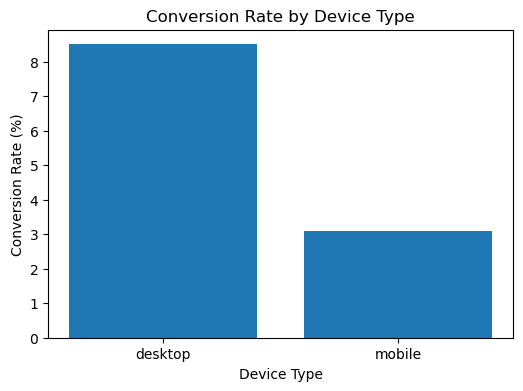

In [111]:
plt.figure(figsize=(6, 4))

plt.bar(
    device_conversion["device_type"],
    device_conversion["Conversion_Rate"]
)

plt.title("Conversion Rate by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Conversion Rate (%)")

plt.show()

In [145]:
repeat_conversion = (
    session_analysis
    .groupby("is_repeat_session")
    .agg(
        Sessions=("website_session_id", "count"),
        Orders=("converted", "sum"),
        Conversion_Rate=("converted", "mean")
    )
    .reset_index()
)

repeat_conversion["Conversion_Rate"] = (
    repeat_conversion["Conversion_Rate"] * 100
).round(2)

repeat_conversion

,is_repeat_session,Sessions,Orders,Conversion_Rate
0,0,394318,26164,6.64
1,1,78553,6149,7.83


In [147]:
session_analysis["utm_source"] = (
    session_analysis["utm_source"].fillna("Other / Direct")
)

In [148]:
source_conversion = (
    session_analysis
    .groupby("utm_source")
    .agg(
        Sessions=("website_session_id", "count"),
        Orders=("converted", "sum"),
        Conversion_Rate=("converted", "mean")
    )
    .reset_index()
)

source_conversion["Conversion_Rate"] = (
    source_conversion["Conversion_Rate"] * 100
).round(2)

source_conversion.sort_values(
    "Conversion_Rate",
    ascending=False
)

,utm_source,Sessions,Orders,Conversion_Rate
0,Other / Direct,83328,6118,7.34
1,bsearch,62823,4519,7.19
2,gsearch,316035,21333,6.75
3,socialbook,10685,343,3.21


In [156]:
session_analysis["utm_campaign"] = (
    session_analysis["utm_campaign"].fillna("Other / Direct")
)

campaign_conversion = (
    session_analysis
    .groupby("utm_campaign")
    .agg(
        Sessions=("website_session_id", "count"),
        Orders=("converted", "sum"),
        Conversion_Rate=("converted", "mean")
    )
    .reset_index()
)

campaign_conversion["Conversion_Rate"] = (
    campaign_conversion["Conversion_Rate"] * 100
).round(2)

campaign_conversion.sort_values(
    "Conversion_Rate",
    ascending=False
)

,utm_campaign,Sessions,Orders,Conversion_Rate
1,brand,41243,3212,7.79
0,Other / Direct,83328,6118,7.34
3,nonbrand,337615,22640,6.71
2,desktop_targeted,5590,288,5.15
4,pilot,5095,55,1.08


In [161]:
conversion_model_data = session_analysis[
    [
        "device_type",
        "is_repeat_session",
        "utm_source",
        "utm_campaign",
        "converted"
    ]
].copy()

In [162]:

conversion_model_data = pd.get_dummies(
    conversion_model_data,
    columns=[
        "device_type",
        "utm_source",
        "utm_campaign"
    ],
    drop_first=True,
    dtype=int
)

In [118]:
X = conversion_model_data.drop("converted", axis=1)
y = conversion_model_data["converted"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (472871, 9)
y shape: (472871,)


In [119]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [120]:
from sklearn.linear_model import LogisticRegression

conversion_model = LogisticRegression(max_iter=1000)

conversion_model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [121]:
conversion_prob = conversion_model.predict_proba(X_test)[:, 1]

In [122]:
from sklearn.metrics import roc_auc_score

conversion_auc = roc_auc_score(
    y_test,
    conversion_prob
)

print(
    "Conversion Model ROC-AUC:",
    round(conversion_auc, 3)
)

Conversion Model ROC-AUC: 0.611


The Logistic Regression model achieved a ROC-AUC of approximately 0.61. This indicates that device type, repeat-session status, traffic source and campaign provide some ability to distinguish converting from non-converting sessions, but the predictive strength is limited. Additional behavioural information may improve future models.

Predictive Model 2 — Order Value Prediction

In [164]:
order_model_data = orders.merge(
    website_sessions[
        [
            "website_session_id",
            "device_type",
            "is_repeat_session",
            "utm_source",
            "utm_campaign"
        ]
    ],
    on="website_session_id",
    how="left"
)

In [166]:
order_model_data["utm_source"] = (
    order_model_data["utm_source"].fillna("Other / Direct")
)

order_model_data["utm_campaign"] = (
    order_model_data["utm_campaign"].fillna("Other / Direct")
)

In [167]:
order_value_data = order_model_data[
    [
        "items_purchased",
        "primary_product_id",
        "device_type",
        "is_repeat_session",
        "utm_source",
        "utm_campaign",
        "price_usd"
    ]
].copy()

In [168]:
order_value_data = pd.get_dummies(
    order_value_data,
    columns=[
        "primary_product_id",
        "device_type",
        "utm_source",
        "utm_campaign"
    ],
    drop_first=True,
    dtype=int
)

In [169]:
X_order = order_value_data.drop(
    "price_usd",
    axis=1
)

y_order = order_value_data["price_usd"]

In [170]:
X_order_train, X_order_test, y_order_train, y_order_test = train_test_split(
    X_order,
    y_order,
    test_size=0.2,
    random_state=42
)

In [129]:
from sklearn.linear_model import LinearRegression

order_value_model = LinearRegression()

order_value_model.fit(
    X_order_train,
    y_order_train
)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [171]:

order_value_pred = order_value_model.predict(
    X_order_test
)

In [174]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [175]:
mae = mean_absolute_error(
    y_order_test,
    order_value_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_order_test,
        order_value_pred
    )
)

r2 = r2_score(
    y_order_test,
    order_value_pred
)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 3))

MAE: 2.59
RMSE: 5.3
R² Score: 0.91


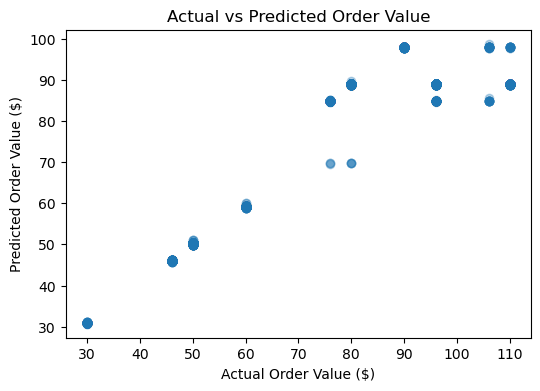

In [176]:
plt.figure(figsize=(6, 4))

plt.scatter(
    y_order_test,
    order_value_pred,
    alpha=0.3
)

plt.xlabel("Actual Order Value ($)")
plt.ylabel("Predicted Order Value ($)")
plt.title("Actual vs Predicted Order Value")

plt.show()

## Key Findings

- Desktop sessions showed a higher conversion rate (8.50%) than mobile sessions (3.09%).
- Repeat sessions converted at 7.83%, compared with 6.64% for new sessions.
- Conversion performance varied across traffic sources and marketing campaigns.
- The Logistic Regression conversion model achieved a ROC-AUC of 0.611, indicating limited but measurable predictive ability using the available session attributes.
- The Linear Regression order value model achieved an R² of 0.910, with an MAE of $2.59 and RMSE of $5.30, indicating strong performance in estimating order value based on the selected order and acquisition characteristics.